# Deep Learning-Based Kidney Stone Detection Using CT Images
**Symbiosis Institute of Technology, Nagpur** | Academic research prototype

## 1. Introduction and objectives
Kidney stones are routinely located on CT, and manual interpretation takes expert time. This notebook builds a
detection and analytics prototype on the dataset that was actually supplied.

**What the dataset supports (verified in section 4):** a Roboflow export (`TEZ_ROI_AUG`) with **YOLO bounding boxes**,
one class (`Tas_Var`, "stone present"), JPG images of 391x320 px, and no masks, patient IDs, DICOM headers or pixel spacing.

**Therefore this notebook implements:**
1. Dataset inspection and validation
2. A single-class YOLOv8 **detector** (localization + confidence)
3. Honest evaluation on the existing `valid` and `test` splits (precision, recall, mAP)
4. False-positive / false-negative analysis
5. **Pixel-based** box measurements (no millimetres, no volume)
6. A dashboard and a Gradio app that runs the trained weights

**Not implemented, because the data cannot support it:** segmentation (Dice/IoU), calibrated size or 3D volume,
classification ROC-AUC (no stone-negative images), and Grad-CAM (applies to CNN classifiers only).

Poster reference figures (about 95% accuracy, Dice about 0.87, size error under 5%) are *targets from the poster*, not results.
All numbers below are produced by running the notebook.

**Run order:** Runtime > Change runtime type > **GPU**, then Run all. Upload the dataset ZIP when asked.

## 2. Library installation

In [1]:
!pip -q install ultralytics gradio plotly seaborn pyyaml tabulate

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 382.1 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.9/97.9 kB 5.6 MB/s eta 0:00:00


## 3. Configuration

In [2]:
import os, sys, zipfile, glob, re, json, hashlib, shutil, random, collections, warnings, time
from pathlib import Path
import numpy as np, pandas as pd, yaml
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import torch
from IPython.display import display, Markdown, HTML
warnings.filterwarnings("ignore")

# ---- settings you may change ----
ZIP_PATH      = os.environ.get("KS_ZIP", "")           # leave empty to upload in Colab
MODEL_NAME    = os.environ.get("KS_MODEL", "yolov8s.pt")
EPOCHS        = int(os.environ.get("KS_EPOCHS", 100))
IMGSZ         = int(os.environ.get("KS_IMGSZ", 640))   # small stones: upscaling 391x320 helps
BATCH         = int(os.environ.get("KS_BATCH", 16))
PATIENCE      = 25
CONF          = 0.25     # operating threshold for qualitative analysis
MATCH_IOU     = 0.5      # IoU for counting a detection as a true positive
FORCE_RETRAIN = False    # True: ignore saved weights and train again
RESUME        = False    # True: resume an interrupted run from last.pt
MOUNT_DRIVE   = False    # True: also keep weights/results on Google Drive
SEED          = 42
# ---------------------------------

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
IN_COLAB = "google.colab" in sys.modules
WORK = Path("/content/kidney_stone") if IN_COLAB else Path("./kidney_stone_work")
WORK.mkdir(parents=True, exist_ok=True)
DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("Colab:", IN_COLAB, "| device:", torch.cuda.get_device_name(0) if DEVICE == 0 else "CPU")
if DEVICE == "cpu":
    print("WARNING: no GPU detected. Training will be very slow. Use Runtime > Change runtime type > GPU.")

if MOUNT_DRIVE and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PERSIST = Path("/content/drive/MyDrive/kidney_stone_project"); PERSIST.mkdir(parents=True, exist_ok=True)
else:
    PERSIST = None

Colab: True | device: Tesla T4


## 4. Dataset upload, safe extraction and structure inspection

In [3]:
if not ZIP_PATH:
    if IN_COLAB:
        from google.colab import files
        print("Upload your dataset ZIP (e.g. archive (1).zip) ...")
        up = files.upload()
        ZIP_PATH = str(WORK / list(up.keys())[0])
        with open(ZIP_PATH, "wb") as f:
            f.write(list(up.values())[0])
    else:
        raise SystemExit("Set ZIP_PATH to your dataset ZIP.")
assert Path(ZIP_PATH).exists(), f"ZIP not found: {ZIP_PATH}"

EXTRACT = WORK / "dataset_raw"
if EXTRACT.exists():
    shutil.rmtree(EXTRACT)
EXTRACT.mkdir(parents=True)

def safe_extract(zip_path, dest):
    dest = Path(dest).resolve()
    with zipfile.ZipFile(zip_path) as z:
        for m in z.infolist():
            target = (dest / m.filename).resolve()
            if not str(target).startswith(str(dest)):      # blocks path traversal (zip-slip)
                raise ValueError(f"Unsafe path in ZIP: {m.filename}")
        z.extractall(dest)

safe_extract(ZIP_PATH, EXTRACT)

# find the dataset root even if the ZIP has extra nesting
yamls = sorted(EXTRACT.rglob("data.yaml"), key=lambda p: len(p.parts))
assert yamls, "No data.yaml found in the ZIP."
ROOT = yamls[0].parent
if len(yamls) > 1:
    print("Multiple data.yaml files found; using the shallowest:", yamls[0])
print("Dataset root:", ROOT)
print("Top-level contents:", sorted(p.name for p in ROOT.iterdir()))

Upload your dataset ZIP (e.g. archive (1).zip) ...


Saving archive (1).zip to archive (1).zip
Dataset root: /content/kidney_stone/dataset_raw
Top-level contents: ['README.dataset.txt', 'README.roboflow.txt', 'data.yaml', 'test', 'train', 'valid']


In [4]:
# ---- data.yaml and README files ----
cfg = yaml.safe_load((ROOT / "data.yaml").read_text())
print("data.yaml:\n" + yaml.safe_dump(cfg, sort_keys=False))
for rd in sorted(ROOT.glob("README*")):
    print("=" * 70, "\n", rd.name, "\n", "=" * 70)
    print(rd.read_text(errors="ignore")[:2500])

# ---- class names / ids ----
names = cfg["names"]
CLASS_NAMES = [names[k] for k in sorted(names)] if isinstance(names, dict) else list(names)
print("Class IDs -> names:", dict(enumerate(CLASS_NAMES)), "| nc in yaml:", cfg.get("nc"))
assert cfg.get("nc", len(CLASS_NAMES)) == len(CLASS_NAMES), "nc does not match number of names"

data.yaml:
train: ../train/images
val: ../valid/images
test: ../test/images
nc: 1
names:
- Tas_Var
roboflow:
  workspace: tez-nwkf5
  project: tez_roi_aug
  version: 3
  license: CC BY 4.0
  url: https://universe.roboflow.com/tez-nwkf5/tez_roi_aug/dataset/3

 README.dataset.txt 
# TEZ_ROI_AUG > 2023-04-28 8:15pm
https://universe.roboflow.com/tez-nwkf5/tez_roi_aug

Provided by a Roboflow user
License: CC BY 4.0


 README.roboflow.txt 

TEZ_ROI_AUG - v3 2023-04-28 8:15pm

This dataset was exported via roboflow.com on August 17, 2023 at 12:11 PM GMT

Roboflow is an end-to-end computer vision platform that helps you
* collaborate with your team on computer vision projects
* collect & organize images
* understand and search unstructured image data
* annotate, and create datasets
* export, train, and deploy computer vision models
* use active learning to improve your dataset over time

For state of the art Computer Vision training notebooks you can use with this dataset,
visit https://github

In [5]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp", ".webp"}

def split_dir(*cands):
    for c in cands:
        if (ROOT / c).exists():
            return ROOT / c
    return None

SPLITS = {"train": split_dir("train"), "valid": split_dir("valid", "val"), "test": split_dir("test")}
print({k: (str(v.relative_to(ROOT)) if v else None) for k, v in SPLITS.items()})
assert all(SPLITS.values()), "train/valid/test folder missing"

# ---- recursive inventory ----
inv = []
for s, d in SPLITS.items():
    files = [p for p in d.rglob("*") if p.is_file()]
    exts = collections.Counter(p.suffix.lower() for p in files)
    inv.append({"split": s, "images": sum(v for k, v in exts.items() if k in IMG_EXT),
                "txt_annotations": exts.get(".txt", 0), "json_annotations": exts.get(".json", 0),
                "dicom_files": exts.get(".dcm", 0),
                "other_files": sum(v for k, v in exts.items() if k not in IMG_EXT | {".txt", ".json", ".dcm"}),
                "extensions": dict(exts)})
inv_df = pd.DataFrame(inv)
display(inv_df)

{'train': 'train', 'valid': 'valid', 'test': 'test'}


,split,images,txt_annotations,json_annotations,dicom_files,other_files,extensions
0,train,1054,1054,0,0,0,"{'.txt': 1054, '.jpg': 1054}"
1,valid,123,123,0,0,0,"{'.txt': 123, '.jpg': 123}"
2,test,123,123,0,0,0,"{'.txt': 123, '.jpg': 123}"


In [6]:
# ---- per-image records: pairing, label parsing, validity ----
def parse_label(path):
    # Returns (rows, kind). kind is 'bbox' (5 cols), 'polygon' (>5 cols, even coords), 'mixed' or 'empty'.
    rows, kinds = [], set()
    for ln in Path(path).read_text().splitlines():
        t = ln.split()
        if not t:
            continue
        vals = [float(x) for x in t]
        if len(vals) == 5:
            kinds.add("bbox")
        elif len(vals) > 5 and (len(vals) - 1) % 2 == 0:
            kinds.add("polygon")
        else:
            kinds.add("invalid")
        rows.append(vals)
    kind = "empty" if not rows else (kinds.pop() if len(kinds) == 1 else "mixed")
    return rows, kind

def source_id(stem):
    return re.sub(r"\.rf\.[0-9a-fA-F]+$", "", stem)      # Roboflow suffix -> original image id

recs, boxes = [], []
for s, d in SPLITS.items():
    lbl = {p.stem: p for p in d.rglob("*.txt")}
    for ip in sorted(p for p in d.rglob("*") if p.suffix.lower() in IMG_EXT):
        w, h = Image.open(ip).size
        lp = lbl.get(ip.stem)
        r = dict(split=s, path=str(ip), stem=ip.stem, src=source_id(ip.stem), w=w, h=h,
                 has_label=lp is not None, n_boxes=0, kind=None, invalid=False,
                 md5=hashlib.md5(ip.read_bytes()).hexdigest())
        if lp is not None:
            rows, kind = parse_label(lp)
            r["kind"], r["n_boxes"] = kind, len(rows)
            for v in rows:
                ok = (int(v[0]) == v[0] and 0 <= int(v[0]) < len(CLASS_NAMES) and all(0 <= x <= 1 for x in v[1:]))
                r["invalid"] |= not ok
                if len(v) == 5:
                    boxes.append(dict(split=s, stem=ip.stem, cls=int(v[0]), xc=v[1], yc=v[2], bw=v[3], bh=v[4], W=w, H=h))
        recs.append(r)
df = pd.DataFrame(recs)
bx = pd.DataFrame(boxes)
bx["w_px"] = bx.bw * bx.W; bx["h_px"] = bx.bh * bx.H
bx["diag_px"] = np.hypot(bx.w_px, bx.h_px); bx["area_px"] = bx.w_px * bx.h_px
print("images:", len(df), "| boxes:", len(bx))

images: 1300 | boxes: 2827


In [7]:
# ---- annotation format decision ----
kinds = df.kind.value_counts(dropna=False).to_dict()
print("Label kinds per image:", kinds)
n_json = int(inv_df.json_annotations.sum())
mask_dirs = [p for p in ROOT.rglob("*") if p.is_dir() and "mask" in p.name.lower()]
if n_json:
    print("JSON annotation files found: inspect manually (possible COCO).")
if mask_dirs:
    print("Mask-like folders found:", mask_dirs)
if set(kinds) <= {"bbox", "empty"} and not n_json and not mask_dirs:
    ANNOTATION_FORMAT = "yolo_bbox"
elif "polygon" in kinds and "bbox" not in kinds:
    ANNOTATION_FORMAT = "yolo_polygon"
else:
    ANNOTATION_FORMAT = "ambiguous"
print("ANNOTATION FORMAT:", ANNOTATION_FORMAT)
assert ANNOTATION_FORMAT == "yolo_bbox", (
    "This notebook is written for YOLO bounding boxes. Your data looks different "
    "- stop and revise the model section before training.")

# ---- quality checks ----
summ = []
for s in SPLITS:
    d = df[df.split == s]; b = bx[bx.split == s]
    summ.append({"split": s, "images": len(d), "boxes": len(b),
                 "missing_labels": int((~d.has_label).sum()),
                 "empty_labels (negatives)": int((d.n_boxes == 0).sum()),
                 "invalid_labels": int(d.invalid.sum()),
                 "unique_source_images": d.src.nunique(),
                 "boxes/img": round(len(b) / max(len(d), 1), 2)})
summary = pd.DataFrame(summ).set_index("split")
display(summary)

# duplicates and leakage
dup_groups = df.groupby("md5").split.agg(list)
dup_groups = dup_groups[dup_groups.map(len) > 1]
print("Exact duplicate file groups:", len(dup_groups), "| across splits:", int(sum(len(set(v)) > 1 for v in dup_groups)))
srcs = {s: set(df[df.split == s].src) for s in SPLITS}
LEAK = {f"{a}&{b}": len(srcs[a] & srcs[b]) for a, b in [("train", "valid"), ("train", "test"), ("valid", "test")]}
print("Shared source-image IDs between splits:", LEAK)
tr = df[df.split == "train"]
print("Train images per source id:", tr.groupby("src").size().value_counts().to_dict(),
      "(2 means Roboflow created 2 augmented copies of the same source image; this stays inside train.)")

# stone-positive / negative
pos, neg = int((df.n_boxes > 0).sum()), int((df.n_boxes == 0).sum())
print(f"\nStone-positive images: {pos} | stone-negative (empty label) images: {neg}")
if neg < 0.05 * len(df):
    print("NOTE: essentially no stone-negative images. Specificity / false-alarm rate on healthy CT "
          "cannot be measured, and ROC-AUC / classification accuracy are not meaningful.")

# metadata
dcm = int(inv_df.dicom_files.sum())
print("\nDICOM files:", dcm, "| pixel spacing / reference size measurements: ",
      "not available (no DICOM headers or measurement files in the ZIP)" if not dcm else "check DICOM headers")
print("Patient identifiers: none provided. Filenames look like DICOM UIDs but are not patient IDs, so "
      "patient-level separation of the splits can NOT be verified.")
print("Image sizes:", df.groupby(["w", "h"]).size().to_dict())

Label kinds per image: {'bbox': 1299, 'empty': 1}
ANNOTATION FORMAT: yolo_bbox


,images,boxes,missing_labels,empty_labels (negatives),invalid_labels,unique_source_images,boxes/img
split,,,,,,,
train,1054,2278,0,1,0,532,2.16
valid,123,325,0,0,0,123,2.64
test,123,224,0,0,0,123,1.82


Exact duplicate file groups: 0 | across splits: 0
Shared source-image IDs between splits: {'train&valid': 0, 'train&test': 0, 'valid&test': 0}
Train images per source id: {2: 522, 1: 10} (2 means Roboflow created 2 augmented copies of the same source image; this stays inside train.)

Stone-positive images: 1299 | stone-negative (empty label) images: 1
NOTE: essentially no stone-negative images. Specificity / false-alarm rate on healthy CT cannot be measured, and ROC-AUC / classification accuracy are not meaningful.

DICOM files: 0 | pixel spacing / reference size measurements:  not available (no DICOM headers or measurement files in the ZIP)
Patient identifiers: none provided. Filenames look like DICOM UIDs but are not patient IDs, so patient-level separation of the splits can NOT be verified.
Image sizes: {(391, 320): 1300}


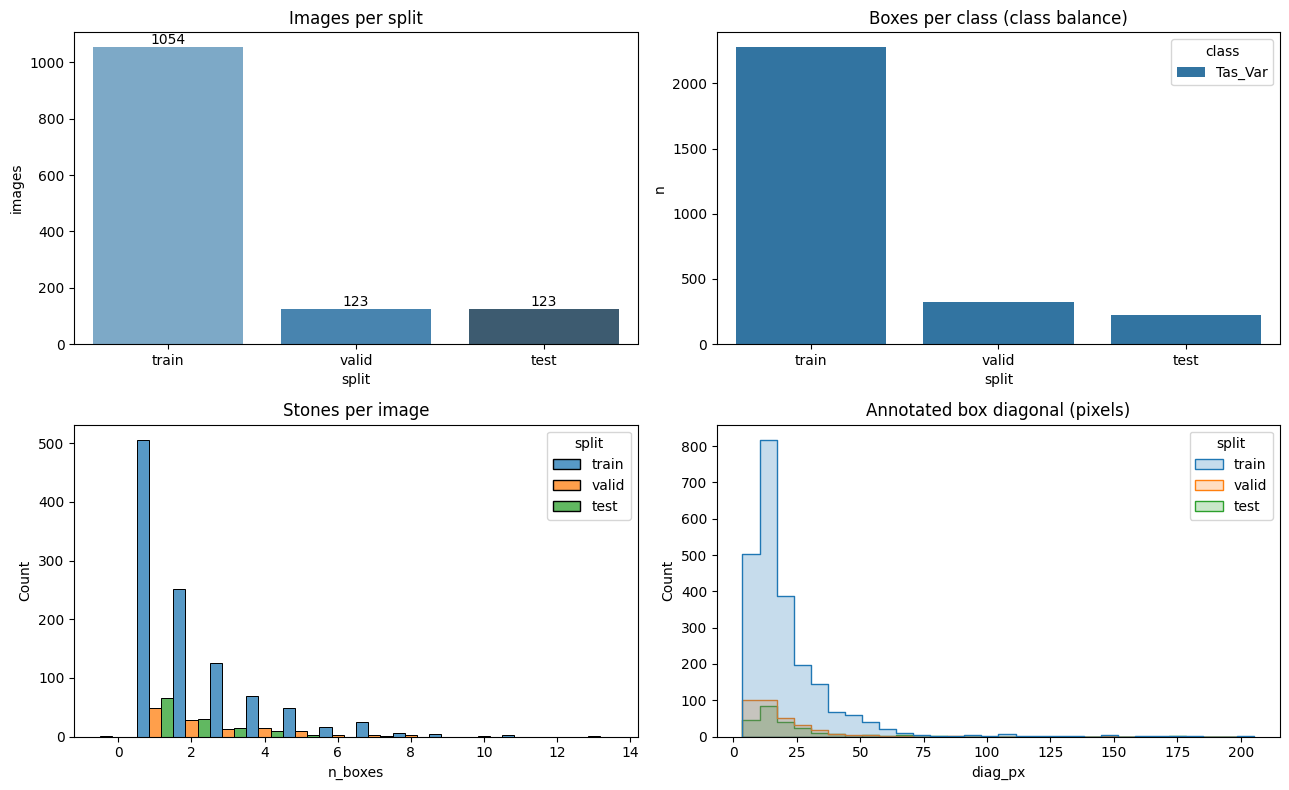

split           test   train  valid
w_px    count  224.0  2278.0  325.0
        mean    14.5    15.3   13.4
        std     11.2    12.3   10.3
        min      3.0     3.0    3.0
        25%      8.0     8.0    7.0
        50%     11.0    11.0   10.0
        75%     18.0    18.0   16.0
        max    113.0   137.0  109.0
h_px    count  224.0  2278.0  325.0
        mean    12.4    13.1   11.1
        std     12.0    11.8    9.4
        min      3.0     2.0    2.0
        25%      6.0     7.0    5.0
        50%     10.0    10.0    8.0
        75%     14.0    16.0   14.0
        max    137.0   153.0  104.0
diag_px count  224.0  2278.0  325.0
        mean    19.2    20.3   17.6
        std     16.2    16.8   13.7
        min      4.2     4.2    3.6
        25%     11.1    10.8    9.4
        50%     14.8    15.3   13.0
        75%     22.9    23.8   21.9
        max    177.6   205.4  150.7

In [8]:
# ---- charts: dataset size, class balance, boxes/image, box size ----
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
order = list(SPLITS)
sns.barplot(x=summary.index, y=summary.images, order=order, ax=ax[0, 0], palette="Blues_d")
ax[0, 0].set_title("Images per split")
for i, v in enumerate(summary.loc[order, "images"]): ax[0, 0].text(i, v, int(v), ha="center", va="bottom")
cc = bx.groupby(["split", "cls"]).size().reset_index(name="n"); cc["class"] = cc.cls.map(dict(enumerate(CLASS_NAMES)))
sns.barplot(data=cc, x="split", y="n", hue="class", order=order, ax=ax[0, 1])
ax[0, 1].set_title("Boxes per class (class balance)")
sns.histplot(data=df, x="n_boxes", hue="split", multiple="dodge", discrete=True, ax=ax[1, 0])
ax[1, 0].set_title("Stones per image")
sns.histplot(data=bx, x="diag_px", hue="split", bins=30, ax=ax[1, 1], element="step")
ax[1, 1].set_title("Annotated box diagonal (pixels)")
plt.tight_layout(); plt.show()
display(bx.groupby("split")[["w_px", "h_px", "diag_px"]].describe().round(1).T)

## 5. Annotation visualization (original annotations overlaid)

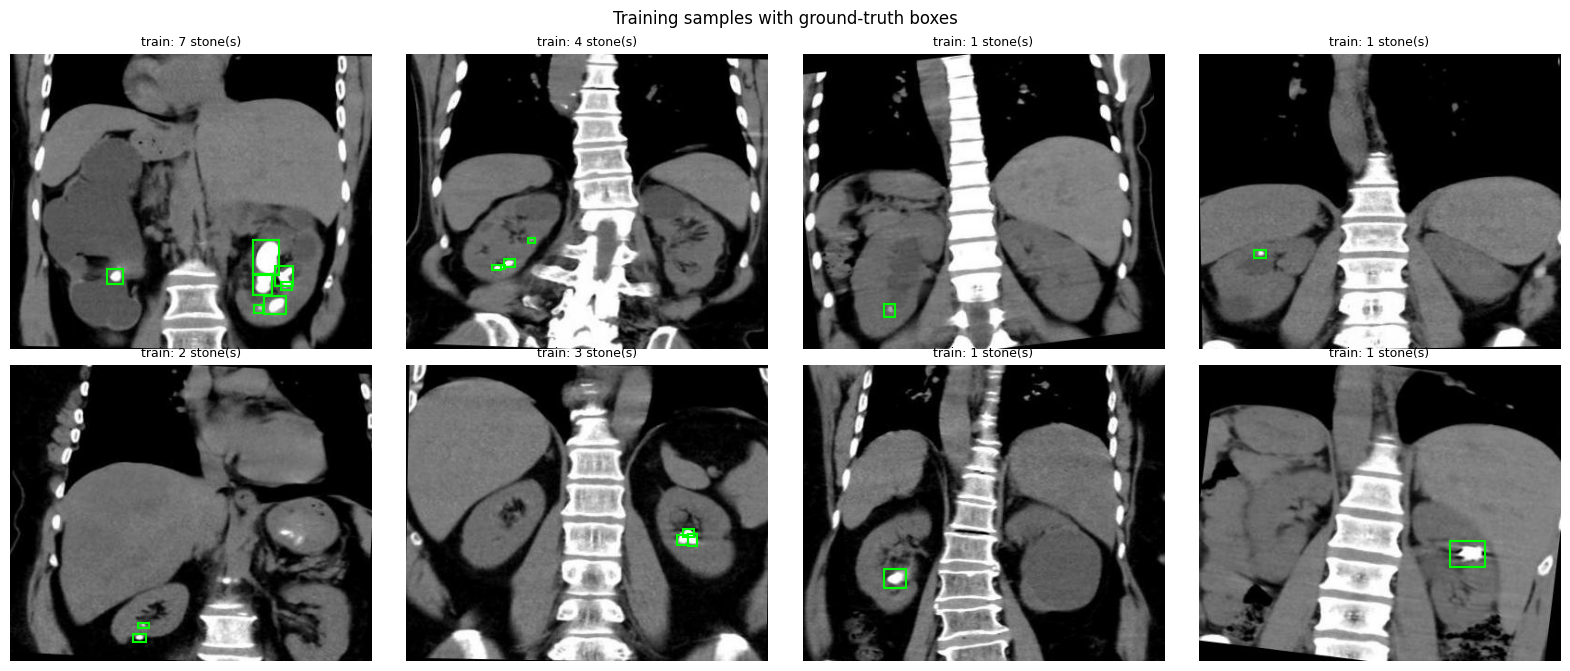

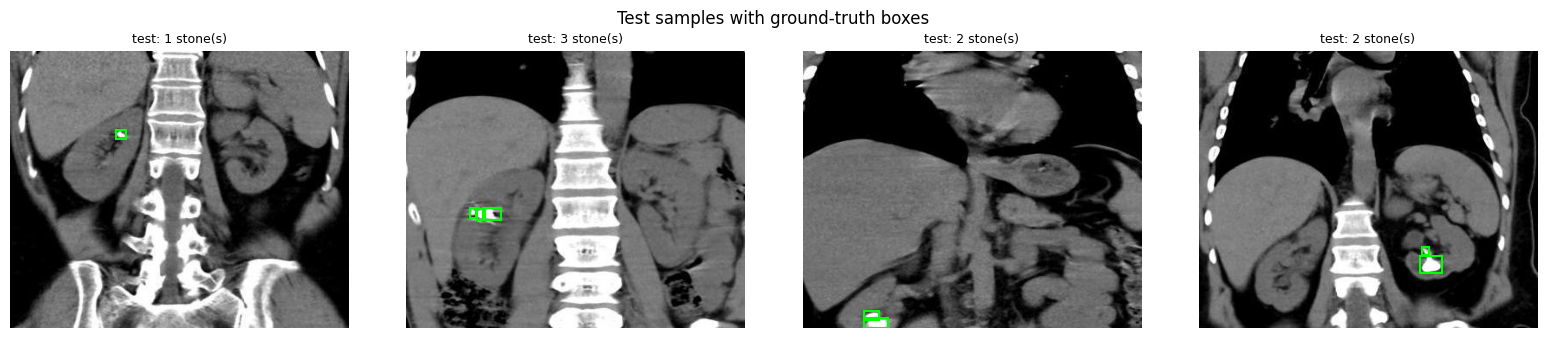

In [9]:
import matplotlib.patches as patches

def show_samples(frame, n=8, title=""):
    sm = frame.sample(min(n, len(frame)), random_state=SEED)
    cols = 4; rows = int(np.ceil(len(sm) / cols))
    fig, axs = plt.subplots(rows, cols, figsize=(4 * cols, 3.4 * rows)); axs = np.atleast_1d(axs).ravel()
    for a in axs: a.axis("off")
    for a, (_, r) in zip(axs, sm.iterrows()):
        a.imshow(Image.open(r.path).convert("RGB"))
        for _, b in bx[bx.stem == r.stem].iterrows():
            a.add_patch(patches.Rectangle(((b.xc - b.bw / 2) * b.W, (b.yc - b.bh / 2) * b.H), b.w_px, b.h_px,
                                          fill=False, ec="lime", lw=1.5))
        a.set_title(f"{r.split}: {r.n_boxes} stone(s)", fontsize=9)
    plt.suptitle(title); plt.tight_layout(); plt.show()

show_samples(df[df.split == "train"], 8, "Training samples with ground-truth boxes")
show_samples(df[df.split == "test"], 4, "Test samples with ground-truth boxes")

## 6. Preprocessing and augmentation
- Images are already 391x320 JPG. Ultralytics letterboxes them to `IMGSZ` and normalizes intensities to 0-1.
  Upscaling to 640 keeps the small stones (about 15 px) detectable.
- **Augmentation is applied to the training split only.** The training split already contains Roboflow copies
  (flip, rotation +/-10 degrees). Ultralytics adds light on-the-fly augmentation: horizontal flip, small rotation, translate, scale,
  brightness (`hsv_v`) and mosaic. Vertical flip is off because kidney anatomy has a fixed up/down orientation in axial CT.
- Valid and test images are never augmented.
- The original `data.yaml` uses relative paths (`../train/images`) that break in Colab, so a corrected YAML with absolute paths is written below.

In [10]:
def img_dir(split):
    d = SPLITS[split]
    return d / "images" if (d / "images").exists() else d

DATA_YAML = WORK / "data_fixed.yaml"
DATA_YAML.write_text(yaml.safe_dump({
    "train": str(img_dir("train").resolve()),
    "val":   str(img_dir("valid").resolve()),
    "test":  str(img_dir("test").resolve()),
    "nc": len(CLASS_NAMES),
    "names": {i: n for i, n in enumerate(CLASS_NAMES)},
}, sort_keys=False))
print(DATA_YAML.read_text())
for k in ("train", "val", "test"):
    p = Path(yaml.safe_load(DATA_YAML.read_text())[k]); assert p.exists(), p
    print(k, "OK ->", len(list(p.glob('*'))), "images")

train: /content/kidney_stone/dataset_raw/train/images
val: /content/kidney_stone/dataset_raw/valid/images
test: /content/kidney_stone/dataset_raw/test/images
nc: 1
names:
  0: Tas_Var

train OK -> 1054 images
val OK -> 123 images
test OK -> 123 images


## 7. Model selection
Annotation format is **YOLO bounding boxes** (Case A), so a single-class **Ultralytics YOLOv8 detector** is used. It is a single stage
that gives location and confidence, which is the most that bounding-box labels can supervise. No second model is trained.
`yolov8s` is a reasonable accuracy/speed balance for a Colab T4. Change `MODEL_NAME` to `yolov8n.pt` for a faster, weaker run or `yolov8m.pt` for a heavier one.

## 8. Model training

In [11]:
from ultralytics import YOLO
RUNS = WORK / "runs"; RUN_NAME = "kidney_stone_yolo"
RUN_DIR = RUNS / RUN_NAME
BEST = RUN_DIR / "weights" / "best.pt"; LAST = RUN_DIR / "weights" / "last.pt"

if PERSIST and (PERSIST / "best.pt").exists() and not BEST.exists():
    BEST.parent.mkdir(parents=True, exist_ok=True); shutil.copy(PERSIST / "best.pt", BEST)
    print("Restored saved weights from Drive.")

if BEST.exists() and not FORCE_RETRAIN and not RESUME:
    print("Found trained weights, skipping training:", BEST, "(set FORCE_RETRAIN=True to retrain)")
else:
    if RESUME and LAST.exists():
        YOLO(str(LAST)).train(resume=True)
    else:
        model = YOLO(MODEL_NAME)
        model.train(data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, device=DEVICE,
                    project=str(RUNS), name=RUN_NAME, exist_ok=True, seed=SEED, patience=PATIENCE,
                    # augmentation: train split only
                    fliplr=0.5, flipud=0.0, degrees=5, translate=0.1, scale=0.3,
                    hsv_h=0.0, hsv_s=0.0, hsv_v=0.2, mosaic=1.0, close_mosaic=10,
                    plots=True, workers=2, verbose=True)
assert BEST.exists(), "Training did not produce best.pt"
if PERSIST: shutil.copy(BEST, PERSIST / "best.pt")
print("Best weights:", BEST)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/kidney_stone/data_fixed.yaml, degrees=5, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fractio

## 9. Evaluation
`valid` was used by Ultralytics for checkpoint selection during training, so **the `test` split is the unbiased result**.
Precision, recall and F1 are reported at the confidence that maximizes F1; mAP is computed over all thresholds.

In [12]:
model = YOLO(str(BEST))

def evaluate(split, name, plots):
    m = model.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE, conf=0.001, iou=0.6,
                  plots=plots, project=str(RUNS), name=name, exist_ok=True, verbose=False)
    p, r = float(m.box.mp), float(m.box.mr)
    return {"precision": p, "recall": r, "f1": 2 * p * r / (p + r + 1e-12),
            "mAP50": float(m.box.map50), "mAP50_95": float(m.box.map)}

res_valid = evaluate("val", "eval_valid", False)
res_test  = evaluate("test", "eval_test", True)
metrics_df = pd.DataFrame({"validation": res_valid, "test": res_test}).round(4)
display(metrics_df)

# epochs actually run (early stopping may end sooner)
rc = pd.read_csv(RUN_DIR / "results.csv"); rc.columns = [c.strip() for c in rc.columns]
METRICS = {"model": MODEL_NAME, "imgsz": IMGSZ, "epochs_run": int(len(rc)), "conf_operating": CONF,
           "valid": res_valid, "test": res_test,
           "images": {s: int((df.split == s).sum()) for s in SPLITS}}
METRICS_PATH = WORK / "metrics.json"; METRICS_PATH.write_text(json.dumps(METRICS, indent=2))
print("Saved", METRICS_PATH)

Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 881.5±251.2 MB/s, size: 17.1 KB)
val: Scanning /content/kidney_stone/dataset_raw/valid/labels.cache... 123 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 123/123 39.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 4.4it/s 1.8s
                   all        123        325      0.795      0.705      0.732      0.279
Speed: 0.8ms preprocess, 9.4ms inference, 0.0ms loss, 0.8ms postprocess per image
Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 14.7±6.6 MB/s, size: 16.2 KB). Use local storage instead of remote/mount

,validation,test
precision,0.7953,0.8016
recall,0.7051,0.7232
f1,0.7475,0.7604
mAP50,0.7315,0.7320
mAP50_95,0.2792,0.2907


Saved /content/kidney_stone/metrics.json


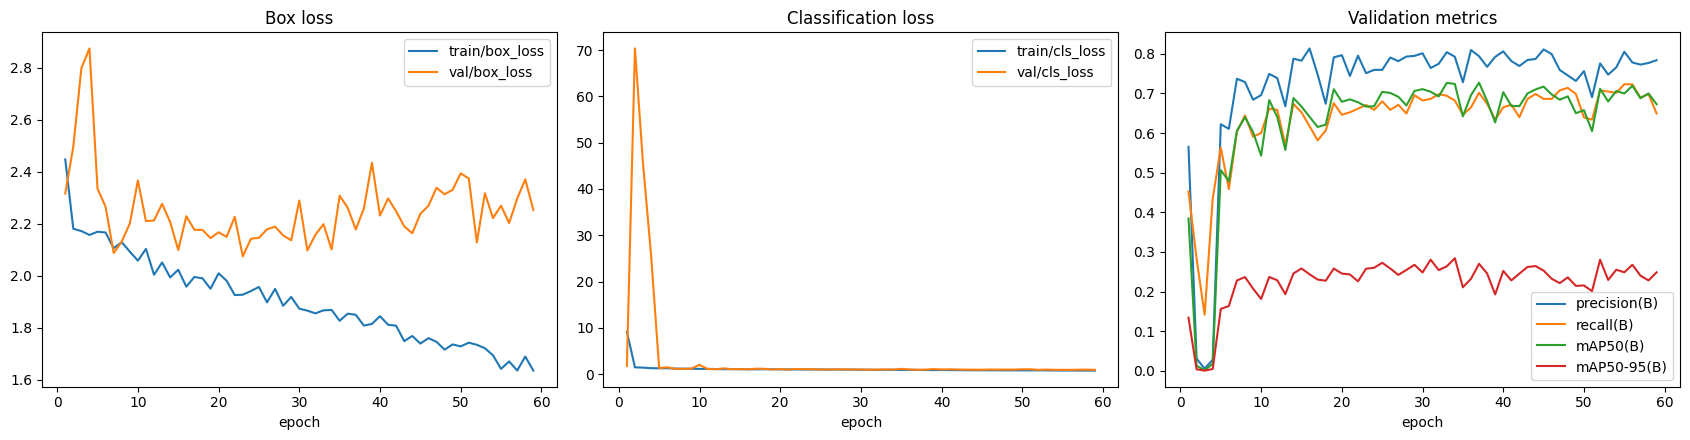

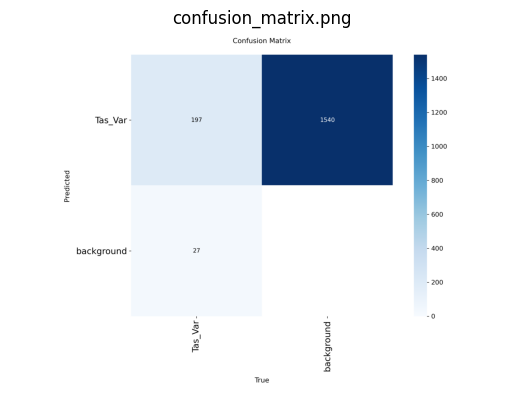

In [13]:
# ---- training and validation curves ----
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for c in ["train/box_loss", "val/box_loss"]: ax[0].plot(rc.epoch, rc[c], label=c)
ax[0].set_title("Box loss"); ax[0].legend(); ax[0].set_xlabel("epoch")
for c in ["train/cls_loss", "val/cls_loss"]: ax[1].plot(rc.epoch, rc[c], label=c)
ax[1].set_title("Classification loss"); ax[1].legend(); ax[1].set_xlabel("epoch")
for c in ["metrics/precision(B)", "metrics/recall(B)", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]:
    ax[2].plot(rc.epoch, rc[c], label=c.replace("metrics/", ""))
ax[2].set_title("Validation metrics"); ax[2].legend(); ax[2].set_xlabel("epoch")
plt.tight_layout(); plt.show()

# ---- curves written by Ultralytics on the test split ----
for f in ["PR_curve.png", "F1_curve.png", "confusion_matrix.png"]:
    p = RUNS / "eval_test" / f
    if p.exists():
        plt.figure(figsize=(6.5, 5)); plt.imshow(Image.open(p)); plt.axis("off"); plt.title(f); plt.show()

**Reading the confusion matrix:** with a single class and no stone-negative images, the only "background" entries are
false alarms (predicted box with no stone) and misses (stone with no box). There are no true negative *images*.

## 10. Prediction visualization, false positives and false negatives

In [14]:
def iou_xyxy(a, b):
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    u = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / u if u > 0 else 0.0

test_df = df[df.split == "test"].reset_index(drop=True)
preds = model.predict(list(test_df.path), conf=CONF, imgsz=IMGSZ, device=DEVICE, verbose=False)

per_img, matched, pred_rows, gt_rows = [], [], [], []
for (_, r), res in zip(test_df.iterrows(), preds):
    g = bx[bx.stem == r.stem]
    gt = [((b.xc - b.bw / 2) * b.W, (b.yc - b.bh / 2) * b.H, (b.xc + b.bw / 2) * b.W, (b.yc + b.bh / 2) * b.H) for _, b in g.iterrows()]
    pr = [(b.xyxy[0].tolist(), float(b.conf[0])) for b in res.boxes]
    pr.sort(key=lambda x: -x[1])
    used, tp = set(), 0
    for box, c in pr:
        pred_rows.append(dict(stem=r.stem, conf=c, w_px=box[2] - box[0], h_px=box[3] - box[1]))
        best, bj = 0, None
        for j, gb in enumerate(gt):
            if j in used: continue
            v = iou_xyxy(box, gb)
            if v > best: best, bj = v, j
        if bj is not None and best >= MATCH_IOU:
            used.add(bj); tp += 1
            gbx = gt[bj]
            matched.append(dict(stem=r.stem, iou=best, conf=c, pw=box[2] - box[0], ph=box[3] - box[1],
                                gw=gbx[2] - gbx[0], gh=gbx[3] - gbx[1]))
    per_img.append(dict(filename=Path(r.path).name, stem=r.stem, gt=len(gt), pred=len(pr), TP=tp, FP=len(pr) - tp, FN=len(gt) - tp))
for _, b in bx[bx.split == "test"].iterrows():
    gt_rows.append(dict(w_px=b.w_px, h_px=b.h_px, diag_px=b.diag_px))

pi = pd.DataFrame(per_img); mt = pd.DataFrame(matched); pdf = pd.DataFrame(pred_rows)
TP, FP, FN = int(pi.TP.sum()), int(pi.FP.sum()), int(pi.FN.sum())
print(f"At conf >= {CONF}, IoU >= {MATCH_IOU}:  TP={TP}  FP={FP}  FN={FN}")
print(f"Precision={TP / max(TP + FP, 1):.3f}  Recall={TP / max(TP + FN, 1):.3f}")
print(f"Images with >=1 miss: {(pi.FN > 0).sum()} | images with >=1 false alarm: {(pi.FP > 0).sum()} | of {len(pi)}")
display(pi.sort_values(["FN", "FP"], ascending=False).head(10))

At conf >= 0.25, IoU >= 0.5:  TP=175  FP=113  FN=49
Precision=0.608  Recall=0.781
Images with >=1 miss: 32 | images with >=1 false alarm: 65 | of 123


,filename,stem,gt,pred,TP,FP,FN
121,1-3-46-670589-33-1-63743022346943480100001-505...,1-3-46-670589-33-1-63743022346943480100001-505...,5,1,0,1,5
50,1-3-46-670589-33-1-63738185833691775600001-559...,1-3-46-670589-33-1-63738185833691775600001-559...,4,3,1,2,3
68,1-3-46-670589-33-1-63738790795811795900001-552...,1-3-46-670589-33-1-63738790795811795900001-552...,3,2,0,2,3
23,1-3-46-670589-33-1-63716409318594992900001-485...,1-3-46-670589-33-1-63716409318594992900001-485...,3,8,1,7,2
42,1-3-46-670589-33-1-63735865531690592300001-489...,1-3-46-670589-33-1-63735865531690592300001-489...,2,2,0,2,2
45,1-3-46-670589-33-1-63737665951722101900001-498...,1-3-46-670589-33-1-63737665951722101900001-498...,3,3,1,2,2
99,1-3-46-670589-33-1-63741294924341752200001-573...,1-3-46-670589-33-1-63741294924341752200001-573...,3,3,1,2,2
38,1-3-46-670589-33-1-63733253864938749700001-468...,1-3-46-670589-33-1-63733253864938749700001-468...,2,1,0,1,2
48,1-3-46-670589-33-1-63738185833351756200001-556...,1-3-46-670589-33-1-63738185833351756200001-556...,4,3,2,1,2
57,1-3-46-670589-33-1-63738371770632051000001-556...,1-3-46-670589-33-1-63738371770632051000001-556...,4,3,2,1,2


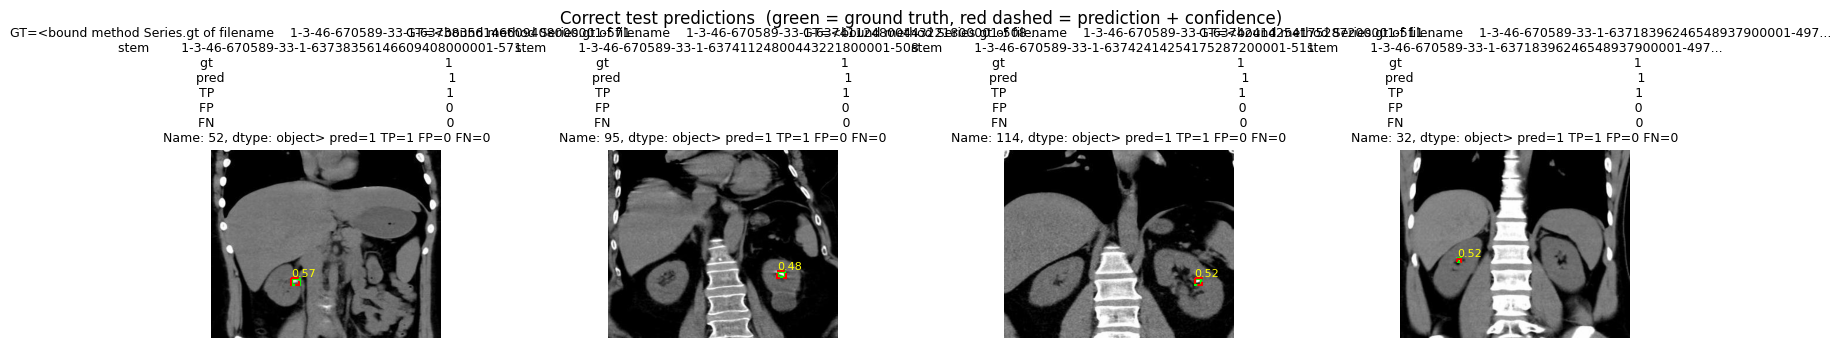

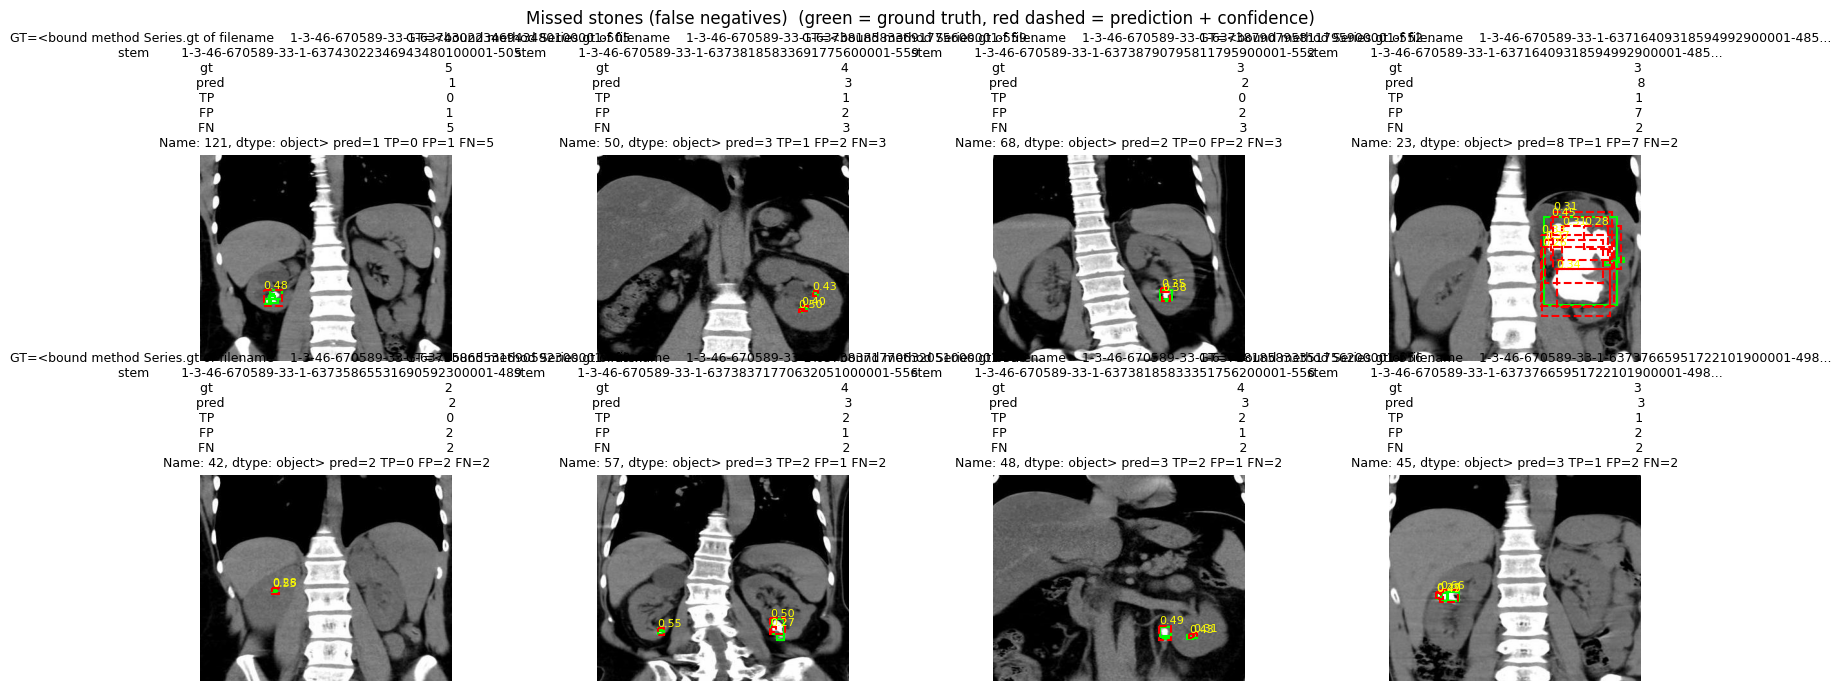

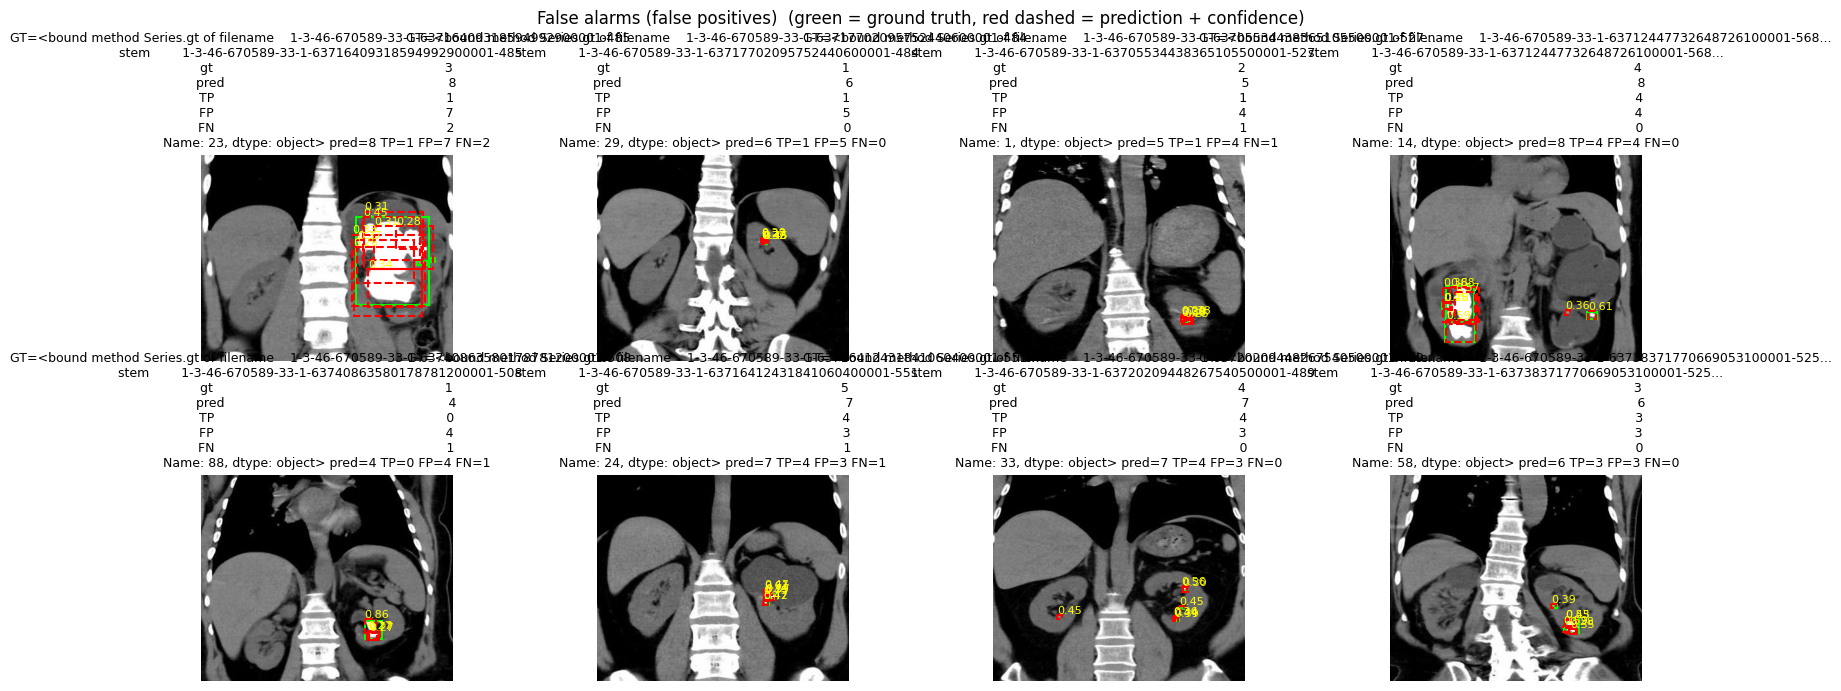

In [16]:
def show_pred_grid(rows, title, n=8):
    rows = rows.head(n); cols = 4; nr = int(np.ceil(len(rows) / cols))
    fig, axs = plt.subplots(nr, cols, figsize=(4 * cols, 3.5 * nr)); axs = np.atleast_1d(axs).ravel()
    for a in axs: a.axis("off")
    for a, (_, p) in zip(axs, rows.iterrows()):
        r = test_df[test_df.stem == p.stem].iloc[0]
        a.imshow(Image.open(r.path).convert("RGB"))
        for _, b in bx[bx.stem == p.stem].iterrows():
            a.add_patch(patches.Rectangle(((b.xc - b.bw / 2) * b.W, (b.yc - b.bh / 2) * b.H), b.w_px, b.h_px, fill=False, ec="lime", lw=1.5))
        res = preds[test_df.index[test_df.stem == p.stem][0]]
        for b in res.boxes:
            x1, y1, x2, y2 = b.xyxy[0].tolist()
            a.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="red", lw=1.5, ls="--"))
            a.text(x1, y1 - 2, f"{float(b.conf[0]):.2f}", color="yellow", fontsize=8)
        a.set_title(f"GT={p.gt} pred={p.pred} TP={p.TP} FP={p.FP} FN={p.FN}", fontsize=9)
    plt.suptitle(title + "  (green = ground truth, red dashed = prediction + confidence)"); plt.tight_layout(); plt.show()

ok_rows = pi[(pi['FN'] == 0) & (pi['FP'] == 0) & (pi['gt'] > 0)]
if len(ok_rows): show_pred_grid(ok_rows.sample(min(4, len(ok_rows)), random_state=SEED), "Correct test predictions")
if (pi['FN'] > 0).any(): show_pred_grid(pi[pi['FN'] > 0].sort_values("FN", ascending=False), "Missed stones (false negatives)")
if (pi['FP'] > 0).any(): show_pred_grid(pi[pi['FP'] > 0].sort_values("FP", ascending=False), "False alarms (false positives)")

## 11. Stone size estimation (pixel-based only)
**What is valid here:** bounding-box width, height, diagonal and box area, in **pixels**.

**What is not valid, and is therefore not reported:**
- millimetres: the images are JPG with no pixel spacing or scale bar;
- volume: single 2D images, no slice spacing, no 3D segmentation;
- a stone "boundary" or true area: boxes are rectangles around the stone, not segmentations.

The comparison below measures how well the *predicted box* agrees with the *annotated box* (both in pixels). It is not an error against a physical ground truth.

,predicted vs annotated box (pixels)
matched_pairs,175.00
MAE width (px),1.96
MAE height (px),1.99
mean |diagonal error| (%),11.60
median |diagonal error| (%),9.80
mean IoU of matched boxes,0.71


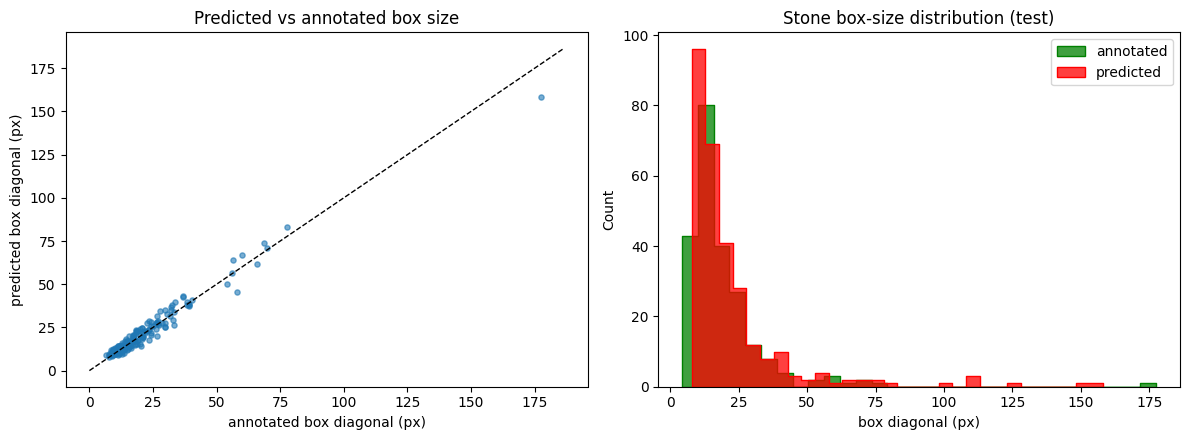

In [17]:
if len(mt):
    mt["w_err_px"] = mt.pw - mt.gw; mt["h_err_px"] = mt.ph - mt.gh
    mt["g_diag"] = np.hypot(mt.gw, mt.gh); mt["p_diag"] = np.hypot(mt.pw, mt.ph)
    mt["diag_rel_err_%"] = 100 * (mt.p_diag - mt.g_diag).abs() / mt.g_diag
    agree = {"matched_pairs": len(mt),
             "MAE width (px)": round(mt.w_err_px.abs().mean(), 2), "MAE height (px)": round(mt.h_err_px.abs().mean(), 2),
             "mean |diagonal error| (%)": round(mt["diag_rel_err_%"].mean(), 1),
             "median |diagonal error| (%)": round(mt["diag_rel_err_%"].median(), 1),
             "mean IoU of matched boxes": round(mt.iou.mean(), 3)}
    display(pd.Series(agree, name="predicted vs annotated box (pixels)").to_frame())
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    ax[0].scatter(mt.g_diag, mt.p_diag, s=14, alpha=.6); lim = [0, max(mt.g_diag.max(), mt.p_diag.max()) * 1.05]
    ax[0].plot(lim, lim, "k--", lw=1); ax[0].set(xlabel="annotated box diagonal (px)", ylabel="predicted box diagonal (px)", title="Predicted vs annotated box size")
    sns.histplot(pd.DataFrame(gt_rows).diag_px, color="green", label="annotated", bins=30, ax=ax[1], element="step")
    sns.histplot(pdf.assign(d=np.hypot(pdf.w_px, pdf.h_px)).d, color="red", label="predicted", bins=30, ax=ax[1], element="step")
    ax[1].set(xlabel="box diagonal (px)", title="Stone box-size distribution (test)"); ax[1].legend()
    plt.tight_layout(); plt.show()
else:
    agree = {}; print("No matched detections to compare.")

## 12. Explainability
Grad-CAM (Selvaraju et al., 2017, cited in your review) explains a **CNN classifier's** decision. This project uses a **detector**, and the dataset has no
image-level negatives for a classifier, so Grad-CAM is **not applied**. Producing a heatmap here would not be
a faithful explanation of the detector. The detector's own explanation is its predicted box and confidence score, shown above.
(If you later add stone-negative images, a classifier with Grad-CAM can be added; remember that a heatmap is not a stone boundary and cannot replace a mask.)

## 13. Healthcare analytics dashboard

In [18]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

fig = make_subplots(rows=3, cols=2, subplot_titles=(
    "Images per split", "Annotated stones per split", "Training / validation box loss",
    "Test metrics (actual)", "Stone box-size distribution (test, px)", "Predicted vs annotated box diagonal (px)"),
    specs=[[{}, {}], [{}, {}], [{}, {}]], vertical_spacing=0.12)
fig.add_trace(go.Bar(x=list(SPLITS), y=[int((df.split == s).sum()) for s in SPLITS], marker_color="#4c78a8", showlegend=False), 1, 1)
fig.add_trace(go.Bar(x=list(SPLITS), y=[int((bx.split == s).sum()) for s in SPLITS], marker_color="#f58518", showlegend=False), 1, 2)
fig.add_trace(go.Scatter(x=rc.epoch, y=rc["train/box_loss"], name="train box loss"), 2, 1)
fig.add_trace(go.Scatter(x=rc.epoch, y=rc["val/box_loss"], name="val box loss"), 2, 1)
fig.add_trace(go.Bar(x=["Precision", "Recall", "F1", "mAP@0.5", "mAP@0.5:0.95"],
                     y=[res_test[k] for k in ["precision", "recall", "f1", "mAP50", "mAP50_95"]], marker_color="#54a24b", showlegend=False), 2, 2)
fig.add_trace(go.Histogram(x=pd.DataFrame(gt_rows).diag_px, name="annotated", opacity=.6, nbinsx=30), 3, 1)
fig.add_trace(go.Histogram(x=np.hypot(pdf.w_px, pdf.h_px), name="predicted", opacity=.6, nbinsx=30), 3, 1)
if len(mt): fig.add_trace(go.Scatter(x=mt.g_diag, y=mt.p_diag, mode="markers", name="matched boxes", marker=dict(size=5)), 3, 2)
fig.update_layout(height=1000, width=1100, barmode="overlay", title="Kidney stone detection analytics (academic prototype)")
fig.write_html(str(WORK / "dashboard.html")); fig.show()
display(Markdown("**Not shown, because unsupported by the data:** Dice/IoU vs masks, ROC-AUC, classification confusion matrix, mm size, volume."))
display(pi.rename(columns={"gt": "annotated_stones", "pred": "predicted_stones"}).drop(columns="stem").head(20))

**Not shown, because unsupported by the data:** Dice/IoU vs masks, ROC-AUC, classification confusion matrix, mm size, volume.

,filename,annotated_stones,predicted_stones,TP,FP,FN
0,1-3-46-670589-33-1-63703718086120120200001-548...,3,3,3,0,0
1,1-3-46-670589-33-1-63705534438365105500001-527...,2,5,1,4,1
2,1-3-46-670589-33-1-63705540012666937300001-567...,1,2,1,1,0
3,1-3-46-670589-33-1-63705542123217653900001-530...,3,4,3,1,0
4,1-3-46-670589-33-1-63705542123253656000001-487...,1,1,1,0,0
5,1-3-46-670589-33-1-63706052409136049800001-488...,1,2,1,1,0
6,1-3-46-670589-33-1-63708127596145343100001-462...,3,6,3,3,0
7,1-3-46-670589-33-1-63709079072689291800001-486...,2,1,1,0,1
8,1-3-46-670589-33-1-63709084528362338400001-491...,1,1,1,0,0
9,1-3-46-670589-33-1-63711136318804220000001-503...,2,2,2,0,0


## 14. Inference module and Gradio interface
The next cell writes `kidney_stone_app.py` (single and batch inference, CSV export, error handling, disclaimer). It loads your trained
`best.pt` and calls `model.predict`, with no mock outputs.

In [19]:
%%writefile kidney_stone_app.py
"""
Kidney stone detection: inference helpers and Gradio interface.

Academic research prototype. NOT a medical device and not a substitute
for professional medical diagnosis.

The model is a YOLO bounding-box detector. Sizes reported here are bounding-box
measurements in PIXELS. The dataset has no pixel spacing, so no millimetre
values are produced.
"""
import json
import tempfile
import time
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, UnidentifiedImageError

ALLOWED_EXT = {".png", ".jpg", ".jpeg", ".tif", ".tiff"}
DISCLAIMER = (
    "**Academic research prototype.** This tool is not a medical device and is not a "
    "substitute for professional medical diagnosis. Outputs may contain false positives "
    "and false negatives and must not be used for clinical decisions."
)
SIZE_NOTE = (
    "Sizes are bounding-box dimensions in **pixels** (uncalibrated). No pixel spacing "
    "is available, so millimetre sizes cannot be given."
)

_MODEL = {"path": None, "model": None}


def load_model(weights):
    """Load (and cache) the trained YOLO weights."""
    from ultralytics import YOLO

    weights = str(weights)
    if _MODEL["path"] != weights:
        if not Path(weights).exists():
            raise FileNotFoundError(f"Trained weights not found: {weights}")
        _MODEL["model"] = YOLO(weights)
        _MODEL["path"] = weights
    return _MODEL["model"]


def load_image(path):
    """Open an image as RGB PIL. Raises ValueError with a readable message."""
    p = Path(str(path))
    ext = p.suffix.lower()
    if ext in (".dcm", ".dicom"):
        raise ValueError(
            "DICOM files are not supported (no validated DICOM pipeline is implemented). "
            "Please export the slice as PNG, JPG or TIFF."
        )
    if ext not in ALLOWED_EXT:
        raise ValueError(
            f"Unsupported file type '{ext or 'none'}'. Allowed: PNG, JPG, JPEG, TIFF."
        )
    try:
        im = Image.open(p)
        im.load()
    except (UnidentifiedImageError, OSError, ValueError) as e:
        raise ValueError(f"Could not read image '{p.name}': {e}")
    if im.mode in ("I;16", "I", "F"):
        a = np.asarray(im).astype(np.float32)
        lo, hi = np.percentile(a, (0.5, 99.5))
        a = np.clip((a - lo) / max(hi - lo, 1e-6), 0, 1)
        im = Image.fromarray((a * 255).astype(np.uint8))
    return im.convert("RGB")


def draw_detections(im, dets):
    out = im.copy()
    d = ImageDraw.Draw(out)
    lw = max(2, int(round(min(out.size) / 150)))
    for i, r in enumerate(dets, 1):
        d.rectangle([r["x1"], r["y1"], r["x2"], r["y2"]], outline=(255, 40, 40), width=lw)
        d.text((r["x1"], max(0, r["y1"] - 12)), f"{i}: {r['confidence']:.2f}", fill=(255, 255, 0))
    return out


def analyze_image(path, weights, conf=0.25, iou=0.5, imgsz=640):
    """Run the trained detector on one image. Returns (original, annotated, detections)."""
    model = load_model(weights)
    im = load_image(path)
    res = model.predict(im, conf=conf, iou=iou, imgsz=imgsz, verbose=False)[0]
    names = model.names
    dets = []
    for b in res.boxes:
        x1, y1, x2, y2 = [float(v) for v in b.xyxy[0].tolist()]
        w, h = x2 - x1, y2 - y1
        dets.append(
            dict(
                x1=x1, y1=y1, x2=x2, y2=y2,
                confidence=float(b.conf[0]),
                class_name=str(names[int(b.cls[0])]),
                width_px=w, height_px=h,
                diagonal_px=(w * w + h * h) ** 0.5,
                box_area_px=w * h,
            )
        )
    dets.sort(key=lambda d: -d["confidence"])
    return im, draw_detections(im, dets), dets


def summary_markdown(name, dets, conf):
    if not dets:
        return (
            f"**{name}**: no stone detected at confidence >= {conf:.2f}.\n\n"
            "A missing detection does not prove that no stone is present: this model only "
            "detects the stone class it was trained on and can miss small stones."
        )
    top = max(dets, key=lambda d: d["box_area_px"])
    return (
        f"**{name}**: {len(dets)} candidate stone(s) detected "
        f"(class `{dets[0]['class_name']}`).\n\n"
        f"- Highest confidence: {max(d['confidence'] for d in dets):.2f}\n"
        f"- Largest box: {top['width_px']:.1f} x {top['height_px']:.1f} px "
        f"(diagonal {top['diagonal_px']:.1f} px)\n\n"
        f"{SIZE_NOTE}"
    )


def detections_table(dets):
    cols = ["#", "class", "confidence", "width_px", "height_px", "diagonal_px", "box_area_px"]
    rows = [
        [i, d["class_name"], round(d["confidence"], 3), round(d["width_px"], 1),
         round(d["height_px"], 1), round(d["diagonal_px"], 1), round(d["box_area_px"], 1)]
        for i, d in enumerate(dets, 1)
    ]
    return pd.DataFrame(rows, columns=cols)


def run_batch(paths, weights, conf=0.25, iou=0.5, imgsz=640, progress=None):
    """Process many images; a failure on one image never stops the batch.

    Returns (summary_df, detail_df, gallery, csv_path).
    """
    rows, detail, gallery = [], [], []
    n = len(paths)
    for i, p in enumerate(paths):
        name = Path(str(p)).name
        if progress is not None:
            progress((i + 1) / max(n, 1), desc=f"Analysing {name} ({i + 1}/{n})")
        try:
            _, ann, dets = analyze_image(p, weights, conf, iou, imgsz)
            top = max(dets, key=lambda d: d["box_area_px"]) if dets else None
            rows.append(
                {
                    "filename": name,
                    "status": "ok",
                    "predicted_class": dets[0]["class_name"] if dets else "none",
                    "detection_status": "Stone detected" if dets else "No stone detected",
                    "n_detections": len(dets),
                    "max_confidence": round(max(d["confidence"] for d in dets), 3) if dets else None,
                    "largest_box_width_px": round(top["width_px"], 1) if top else None,
                    "largest_box_height_px": round(top["height_px"], 1) if top else None,
                    "largest_box_diagonal_px": round(top["diagonal_px"], 1) if top else None,
                    "size_unit": "pixels (uncalibrated)",
                    "error": "",
                }
            )
            for j, d in enumerate(dets, 1):
                detail.append({"filename": name, "detection": j, **{k: round(v, 3) if isinstance(v, float) else v for k, v in d.items()}})
            gallery.append((ann, f"{name}: {len(dets)} detection(s)"))
        except Exception as e:  # keep going
            rows.append(
                {
                    "filename": name, "status": "failed", "predicted_class": "",
                    "detection_status": "Failed", "n_detections": None, "max_confidence": None,
                    "largest_box_width_px": None, "largest_box_height_px": None,
                    "largest_box_diagonal_px": None, "size_unit": "", "error": str(e),
                }
            )
    summary = pd.DataFrame(rows)
    detail_df = pd.DataFrame(detail)
    out_dir = Path(tempfile.mkdtemp())
    csv_path = out_dir / f"kidney_stone_batch_{time.strftime('%Y%m%d_%H%M%S')}.csv"
    summary.to_csv(csv_path, index=False)
    return summary, detail_df, gallery, str(csv_path)


def _performance_markdown(metrics_path):
    if not metrics_path or not Path(metrics_path).exists():
        return "No evaluation file found. Run the evaluation section of the notebook first."
    m = json.loads(Path(metrics_path).read_text())
    t = m.get("test", {})
    v = m.get("valid", {})
    lines = [
        "### Model performance (measured by the notebook)",
        f"Model: `{m.get('model', '?')}`, image size {m.get('imgsz', '?')}, "
        f"{m.get('epochs_run', '?')} epochs run.",
        "",
        "| Metric | Validation | Test |",
        "|---|---|---|",
    ]
    for key, label in [("precision", "Precision"), ("recall", "Recall"), ("f1", "F1"),
                       ("mAP50", "mAP@0.5"), ("mAP50_95", "mAP@0.5:0.95")]:
        lines.append(f"| {label} | {v.get(key, float('nan')):.3f} | {t.get(key, float('nan')):.3f} |")
    lines += [
        "",
        "Precision, recall and F1 are taken at the confidence that maximises F1.",
        "Segmentation Dice/IoU and calibrated size error are **not available** because the "
        "dataset has only bounding-box annotations and no pixel spacing.",
    ]
    return "\n".join(lines)


def build_ui(weights, metrics_path=None, default_conf=0.25, imgsz=640):
    """Build the Gradio Blocks app. Every prediction comes from the trained weights."""
    import gradio as gr

    load_model(weights)  # fail early if weights are missing
    file_types = sorted(ALLOWED_EXT)

    def single(file, conf, iou, progress=gr.Progress()):
        if file is None:
            return None, None, "Please upload an image first.", pd.DataFrame()
        path = file if isinstance(file, str) else getattr(file, "name", str(file))
        try:
            progress(0.3, desc="Running detector...")
            orig, ann, dets = analyze_image(path, weights, conf, iou, imgsz)
            return orig, ann, summary_markdown(Path(path).name, dets, conf), detections_table(dets)
        except Exception as e:
            return None, None, f"**Error:** {e}", pd.DataFrame()

    def batch(files, conf, iou, progress=gr.Progress()):
        if not files:
            return [], pd.DataFrame(), None, "Please upload one or more images."
        paths = [f if isinstance(f, str) else getattr(f, "name", str(f)) for f in files]
        summary, _, gallery, csv_path = run_batch(paths, weights, conf, iou, imgsz, progress)
        ok = int((summary["status"] == "ok").sum())
        msg = f"Processed {len(paths)} file(s): {ok} succeeded, {len(paths) - ok} failed."
        return gallery, summary, csv_path, msg

    with gr.Blocks(title="Kidney Stone Detection (CT)", theme=gr.themes.Soft()) as demo:
        gr.Markdown(
            "# Kidney Stone Detection in CT Images\n"
            "Deep learning-based detection (YOLO) of kidney stones with pixel-based box "
            "measurements. Symbiosis Institute of Technology, Nagpur: academic project."
        )
        gr.Markdown(DISCLAIMER)
        with gr.Row():
            conf = gr.Slider(0.05, 0.95, value=default_conf, step=0.05, label="Confidence threshold")
            iou = gr.Slider(0.1, 0.9, value=0.5, step=0.05, label="NMS IoU threshold")
        with gr.Tabs():
            with gr.Tab("Single image"):
                f1 = gr.File(label="Upload one CT image (PNG, JPG, JPEG, TIFF)",
                             file_count="single", file_types=file_types, type="filepath")
                b1 = gr.Button("Analyze", variant="primary")
                with gr.Row():
                    o_orig = gr.Image(label="Original image", type="pil")
                    o_pred = gr.Image(label="Detection (bounding boxes + confidence)", type="pil")
                o_sum = gr.Markdown()
                o_tab = gr.Dataframe(label="Detections and pixel measurements", wrap=True, interactive=False)
                b1.click(single, [f1, conf, iou], [o_orig, o_pred, o_sum, o_tab])
            with gr.Tab("Batch testing"):
                f2 = gr.File(label="Upload multiple CT images", file_count="multiple",
                             file_types=file_types, type="filepath")
                b2 = gr.Button("Analyze batch", variant="primary")
                msg = gr.Markdown()
                gal = gr.Gallery(label="Predictions", columns=4, height="auto")
                tab = gr.Dataframe(label="Batch results", wrap=True, interactive=False)
                csv = gr.File(label="Download results (CSV)")
                b2.click(batch, [f2, conf, iou], [gal, tab, csv, msg])
            with gr.Tab("Model performance"):
                gr.Markdown(_performance_markdown(metrics_path))
            with gr.Tab("About / limitations"):
                gr.Markdown(
                    "- Detector trained on bounding-box annotations only: no segmentation mask, "
                    "no Dice/IoU, no 3D volume.\n"
                    f"- {SIZE_NOTE}\n"
                    "- No stone-negative images were present in the training data, so the model has "
                    "not been evaluated on healthy CT images.\n"
                    "- DICOM input is not supported."
                )
        gr.Markdown(DISCLAIMER)
    return demo

Writing kidney_stone_app.py


In [ ]:
import importlib, kidney_stone_app
importlib.reload(kidney_stone_app)
from kidney_stone_app import run_batch, analyze_image, build_ui

# ---- single-image and batch tests on REAL test images ----
sample_paths = list(test_df.path[:5]) + ["not_an_image.txt"]       # last one deliberately invalid
Path("not_an_image.txt").write_text("hello")
summary_df, detail_df, gallery, csv_path = run_batch(sample_paths, BEST, conf=CONF, imgsz=IMGSZ)
display(summary_df)                                                  # invalid file fails, batch continues
print("CSV exported to:", csv_path)
shutil.copy(csv_path, WORK / "sample_batch_results.csv")

orig, ann, dets = analyze_image(test_df.path[0], BEST, conf=CONF, imgsz=IMGSZ)
fig, ax = plt.subplots(1, 2, figsize=(10, 4)); ax[0].imshow(orig); ax[0].set_title("Original"); ax[1].imshow(ann); ax[1].set_title(f"Prediction ({len(dets)} detection(s))")
for a in ax: a.axis("off")
plt.savefig(WORK / "sample_inference.png", dpi=150, bbox_inches="tight"); plt.show()
display(pd.DataFrame(dets).round(2))

In [21]:
from kidney_stone_app import build_ui

demo = build_ui(BEST, METRICS_PATH, default_conf=CONF, imgsz=IMGSZ)
demo.launch(share=True, debug=False)     # open the public link; upload one or many CT images

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9a0880d85ab5a8583a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 15. Saving and reloading trained weights

In [22]:
FINAL = WORK / "kidney_stone_best.pt"
shutil.copy(BEST, FINAL)
reloaded = YOLO(str(FINAL))
a = len(model.predict(test_df.path[0], conf=CONF, imgsz=IMGSZ, device=DEVICE, verbose=False)[0].boxes)
b = len(reloaded.predict(test_df.path[0], conf=CONF, imgsz=IMGSZ, device=DEVICE, verbose=False)[0].boxes)
print("Detections original / reloaded:", a, b, "-> identical" if a == b else "-> MISMATCH")
if PERSIST:
    for f in [FINAL, METRICS_PATH, WORK / "dashboard.html"]: shutil.copy(f, PERSIST / f.name)
    print("Copied to Drive:", PERSIST)

# To reuse the weights in a new session:  put kidney_stone_best.pt next to the notebook, then
#   from kidney_stone_app import build_ui; build_ui("kidney_stone_best.pt").launch(share=True)

Detections original / reloaded: 3 3 -> identical


## 16. README and downloadable bundle

In [23]:
README = f'''# Kidney Stone Detection (CT) - academic prototype

## Dataset (as inspected)
Roboflow export `TEZ_ROI_AUG` v3 (CC BY 4.0): `data.yaml`, `train/`, `valid/`, `test/`, each with `images/` and `labels/`.
YOLO bounding boxes, 1 class (`{CLASS_NAMES[0]}`), JPG {int(df.w.mode()[0])}x{int(df.h.mode()[0])}.
Images: train {METRICS['images']['train']}, valid {METRICS['images']['valid']}, test {METRICS['images']['test']}.

## What is and is not supported
Supported: detection, pixel-based box size. Not supported (no data): segmentation masks / Dice, millimetre size (no pixel spacing),
3D volume, ROC-AUC (no stone-negative images), Grad-CAM (detector, not classifier), DICOM input.

## Run
1. Colab: Runtime > GPU. Open `kidney_stone_detection.ipynb` and Run all; upload the dataset ZIP when prompted.
2. Training writes `kidney_stone_best.pt`, `metrics.json`, `dashboard.html`.
3. The last cell launches the Gradio app (single image, batch, CSV export).

## Test new images
Use the Gradio app, or in Python:
    from kidney_stone_app import run_batch
    summary, details, gallery, csv = run_batch(["my_ct.png"], "kidney_stone_best.pt")
Allowed: PNG, JPG, JPEG, TIFF.

## Test results (measured)
{pd.DataFrame({"validation": res_valid, "test": res_test}).round(3).to_markdown()}

## Missing data that blocks full size estimation
Segmentation masks, pixel spacing (mm/pixel) or DICOM headers, slice spacing for volume, reference size measurements, patient IDs
(for patient-level split verification), stone-negative images.

Academic research prototype. Not for clinical use.
'''
(WORK / "README.md").write_text(README); print(README)

bundle = WORK / "kidney_stone_bundle"
if bundle.exists(): shutil.rmtree(bundle)
bundle.mkdir()
for f in [FINAL, METRICS_PATH, WORK / "dashboard.html", WORK / "README.md", WORK / "sample_inference.png",
          WORK / "sample_batch_results.csv", Path("kidney_stone_app.py"), DATA_YAML, RUN_DIR / "results.csv"]:
    if Path(f).exists(): shutil.copy(f, bundle)
for f in ["PR_curve.png", "F1_curve.png", "confusion_matrix.png"]:
    if (RUNS / "eval_test" / f).exists(): shutil.copy(RUNS / "eval_test" / f, bundle / f"test_{f}")
ZIP_OUT = shutil.make_archive(str(WORK / "kidney_stone_bundle"), "zip", bundle)
print("Bundle:", ZIP_OUT)
if IN_COLAB:
    from google.colab import files; files.download(ZIP_OUT)

# Kidney Stone Detection (CT) - academic prototype

## Dataset (as inspected)
Roboflow export `TEZ_ROI_AUG` v3 (CC BY 4.0): `data.yaml`, `train/`, `valid/`, `test/`, each with `images/` and `labels/`.
YOLO bounding boxes, 1 class (`Tas_Var`), JPG 391x320.
Images: train 1054, valid 123, test 123.

## What is and is not supported
Supported: detection, pixel-based box size. Not supported (no data): segmentation masks / Dice, millimetre size (no pixel spacing),
3D volume, ROC-AUC (no stone-negative images), Grad-CAM (detector, not classifier), DICOM input.

## Run
1. Colab: Runtime > GPU. Open `kidney_stone_detection.ipynb` and Run all; upload the dataset ZIP when prompted.
2. Training writes `kidney_stone_best.pt`, `metrics.json`, `dashboard.html`.
3. The last cell launches the Gradio app (single image, batch, CSV export).

## Test new images
Use the Gradio app, or in Python:
    from kidney_stone_app import run_batch
    summary, details, gallery, csv = run_batch(["my_ct.png"], "kidney_s

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 17. Results, discussion and limitations

In [ ]:
poster = pd.DataFrame([
    ["Detection accuracy", "~95%", f"Not a standard detection metric. Test precision {res_test['precision']:.3f}, recall {res_test['recall']:.3f}, mAP@0.5 {res_test['mAP50']:.3f}"],
    ["Segmentation Dice", "~0.87", "Not computed: no segmentation masks in the dataset"],
    ["Size-estimation error", "< 5%", "Not computed: no pixel spacing or reference measurements. Box-diagonal agreement (pixels, vs annotated box): "
                                      + (f"mean {agree['mean |diagonal error| (%)']}%" if agree else "n/a")],
], columns=["Poster reference", "Poster value", "This experiment"])
display(poster)

### Interpretation guide
- Compare **test** metrics (unbiased) with **validation** metrics. A large gap suggests overfitting to the validation split used for checkpoint selection.
- mAP@0.5:0.95 is lower than mAP@0.5 for small objects: a 1-2 px shift moves IoU a lot on a 15 px stone.
- Poster figures are targets. Differences from them are expected, and they should be reported as measured, not tuned.

### Limitations
1. **Detection only.** Boxes cannot give a true stone boundary, Dice/IoU against masks, or volume.
2. **No physical units.** No pixel spacing, so all sizes are pixels. The poster's "<5% size error" cannot be validated.
3. **No stone-negative images.** False-alarm behaviour on normal kidneys and image-level specificity are unmeasured. A "no detection" result is not a verified negative.
4. **Split leakage cannot be fully ruled out.** Source images and exact duplicates do not overlap between splits, but there are no patient IDs; slices from one patient may appear in several splits.
5. **Augmented training set.** Train holds Roboflow-augmented copies of 532 source images (2x). Valid and test are un-augmented, which is the correct way round.
6. **Cropped ROI images.** The inputs look like pre-cropped kidney regions, so the model has not been shown to work on full CT slices.
7. **Small, single-source dataset.** Generalization to other scanners and hospitals is unknown (also a challenge listed on your poster).
8. **Academic prototype.** Not validated for clinical use.

### Data needed to complete size estimation
Segmentation masks (or polygons), pixel spacing or DICOM headers, slice thickness/spacing for 3D, reference measurements in mm, patient IDs, and stone-negative images.